In [ ]:
import numpy as np
import matplotlib.pyplot as plt

a = 1
w = np.logspace(-2, 2, 1000)

# Exact magnitude and phase
mag = -10 * np.log10(1 + (w/a)**2)
phase = -np.degrees(np.arctan(w/a))

# Magnitude asymptotes
mag_asym = np.where(w <= a, 0, -20*np.log10(w/a))

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

for ax in axes:
    ax.set_xscale("log")
    ax.set_xlim(0.01, 100)
    ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
    ax.tick_params(length=0, pad=7)
    ax.grid(False)
    ax.axvline(a, ls=":", color="gray", lw=1.2)

# Magnitude plot
ax = axes[0]
ax.set_ylim(-47, 13)
ax.plot(w, mag, lw=2, label="Exact")
ax.plot(w, mag_asym, ":", lw=2.5, label="Asymptotes")
ax.axhline(0, color="black", lw=1)
ax.plot(a, 0, "o", color="green")
ax.text(0.017, 3, "0 dB/decade")
ax.text(4, -16, "-20 dB/decade", rotation=-25)
ax.text(a*1.14, 7, r"$\omega_c=a=1$")
ax.set_ylabel("Magnitude (dB)")
ax.set_title(r"Magnitude: $G(s)=a/(s+a)$")
ax.legend(loc="lower left", frameon=False)

# Phase plot
ax = axes[1]
ax.set_ylim(-110, 14)

# Exact response
ax.plot(w, phase, lw=2, label="Exact")

# Step asymptotes
ax.plot([w[0], a], [0, 0], ":", color="tab:orange", lw=2.5)
ax.plot([a, a], [0, -90], ":", color="tab:orange", lw=2.5)
ax.plot([a, w[-1]], [-90, -90], ":", color="tab:orange",
        lw=2.5, label="Asymptotes")

ax.axhline(0, color="black", lw=1)
ax.plot(a, -45, "o", color="green")
ax.text(a*1.12, -39, r"$-45^\circ$ at $\omega_c$")
ax.text(0.014, -8, r"$0^\circ$")
ax.text(16, -84, r"$-90^\circ$")
ax.set_ylabel("Phase (degrees)")
ax.set_xlabel(r"Angular frequency $\omega$ (rad/s)")
ax.set_title("Phase")

plt.tight_layout()
plt.show()


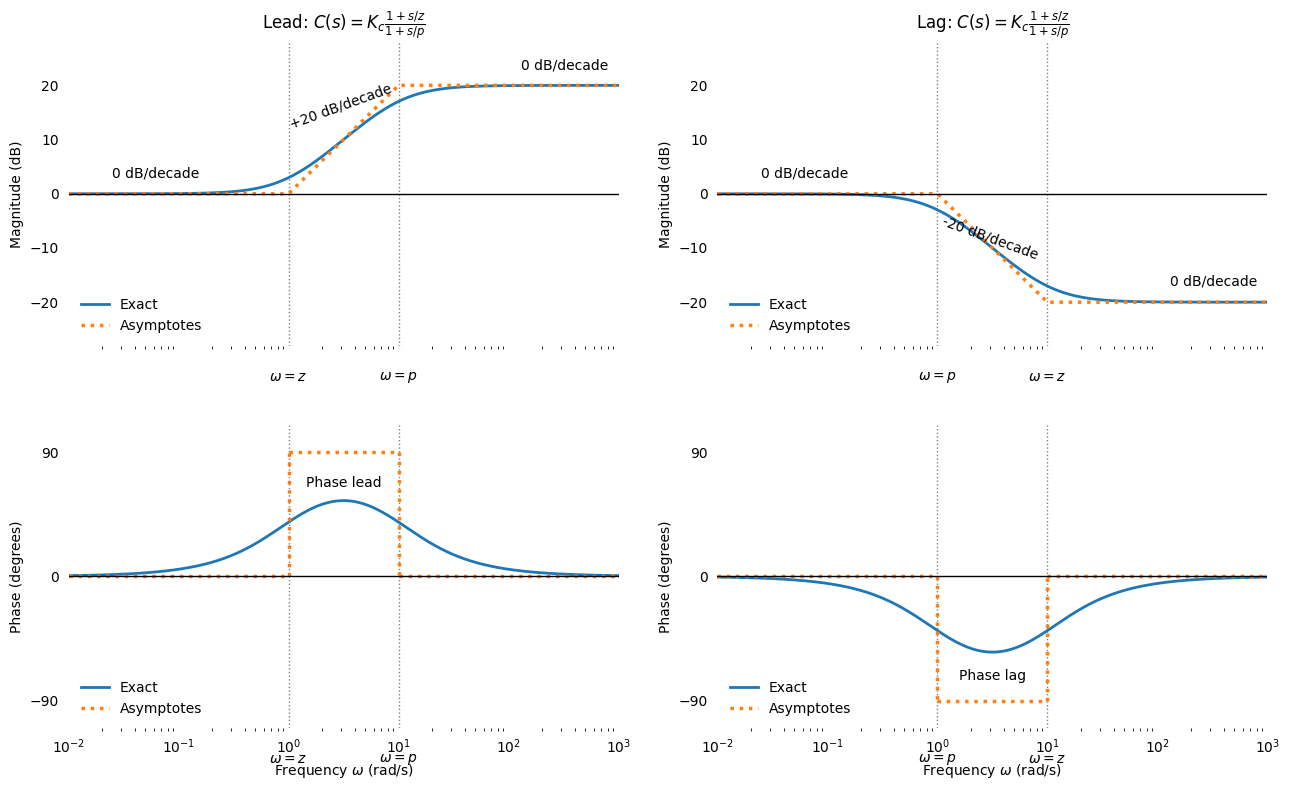

In [1]:

import numpy as np
import matplotlib.pyplot as plt

Kc = 1
configs = [
    ("Lead", 1, 10),
    ("Lag", 10, 1)
]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)

for col, (name, z, p) in enumerate(configs):
    w = np.logspace(-2, 3, 1500)

    # C(s) = Kc*(1+s/z)/(1+s/p)
    C = Kc * (1 + 1j*w/z) / (1 + 1j*w/p)

    mag = 20*np.log10(np.abs(C))
    phase = np.degrees(np.angle(C))

    # Magnitude asymptotes
    mag_asym = (
        20*np.log10(Kc)
        + 20*np.log10(np.maximum(1, w/z))
        - 20*np.log10(np.maximum(1, w/p))
    )

    # Phase step asymptotes
    phase_asym = np.where(
        w < min(z, p), 0,
        np.where(w < max(z, p),
                 90 if z < p else -90, 0)
    )

    ax_m = axes[0, col]
    ax_p = axes[1, col]

    for ax in (ax_m, ax_p):
        ax.set_xscale("log")
        ax.set_xlim(0.01, 1000)
        ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
        ax.tick_params(length=0, pad=7)
        ax.grid(False)

        # Symbolic corner frequencies
        for freq, symbol in [(z, "z"), (p, "p")]:
            ax.axvline(freq, color="gray", ls=":", lw=1)
            ax.text(freq, -0.08, rf"$\omega={symbol}$",
                    transform=ax.get_xaxis_transform(),
                    ha="center", va="top", fontsize=10)

    # Magnitude
    ax_m.plot(w, mag, lw=2, label="Exact")
    ax_m.plot(w, mag_asym, ":", lw=2.5,
              label="Asymptotes")

    ax_m.axhline(0, color="black", lw=1)
    ax_m.set_ylim(-28, 28)
    ax_m.set_title(rf"{name}: $C(s)=K_c\frac{{1+s/z}}{{1+s/p}}$")
    ax_m.set_ylabel("Magnitude (dB)")

    ax_m.text(0.025, 3, "0 dB/decade")
    ax_m.text(130, 23 if z < p else -17,
              "0 dB/decade")

    ax_m.text(
        3, 12 if z < p else -12,
        "+20 dB/decade" if z < p else "-20 dB/decade",
        rotation=20 if z < p else -20,
        ha="center"
    )

    ax_m.legend(loc="lower left", frameon=False)

    # Phase
    ax_p.plot(w, phase, lw=2, label="Exact")

    # Horizontal phase asymptotes with vertical jumps
    f1, f2 = min(z, p), max(z, p)
    peak = 90 if z < p else -90

    ax_p.plot([w[0], f1], [0, 0], ":",
              color="tab:orange", lw=2.5)
    ax_p.plot([f1, f1], [0, peak], ":",
              color="tab:orange", lw=2.5)
    ax_p.plot([f1, f2], [peak, peak], ":",
              color="tab:orange", lw=2.5)
    ax_p.plot([f2, f2], [peak, 0], ":",
              color="tab:orange", lw=2.5)
    ax_p.plot([f2, w[-1]], [0, 0], ":",
              color="tab:orange", lw=2.5,
              label="Asymptotes")

    ax_p.axhline(0, color="black", lw=1)
    ax_p.set_ylim(-110, 110)
    ax_p.set_yticks([-90, 0, 90])
    ax_p.set_ylabel("Phase (degrees)")
    ax_p.set_xlabel(r"Frequency $\omega$ (rad/s)")

    ax_p.text(
        np.sqrt(z*p),
        65 if z < p else -75,
        "Phase lead" if z < p else "Phase lag",
        ha="center"
    )

    ax_p.legend(loc="lower left", frameon=False)

plt.tight_layout(h_pad=3, w_pad=2)
plt.show()


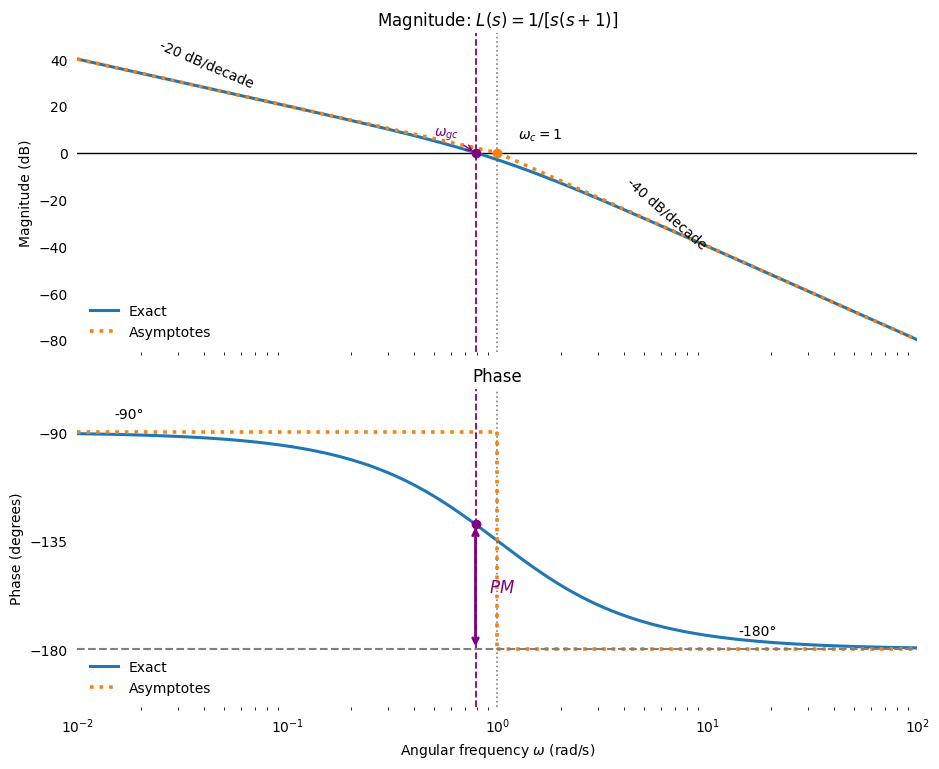

In [5]:

import numpy as np
import matplotlib.pyplot as plt

w = np.logspace(-2, 2, 1200)
wc = 1.0

# Exact frequency response
mag = -20*np.log10(w) - 10*np.log10(1+w**2)
phase = -90 - np.degrees(np.arctan(w))

# Gain crossover and phase margin
wgc = np.sqrt((np.sqrt(5)-1)/2)
phase_gc = -90 - np.degrees(np.arctan(wgc))
PM = 180 + phase_gc

# Magnitude asymptotes
mag_asym = np.where(w <= wc,
                    -20*np.log10(w),
                    -40*np.log10(w))

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(9.5, 7.8), sharex=True
)

for ax in (ax1, ax2):
    ax.set_xscale("log")
    ax.set_xlim(0.01, 100)
    ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
    ax.tick_params(length=0, pad=7)
    ax.axvline(wc, ls=":", color="gray", lw=1.2)
    ax.axvline(wgc, ls="--", color="purple", lw=1.3)

# Magnitude plot
ax1.set_ylim(-85, 51)
ax1.axhline(0, color="black", lw=1)
ax1.plot(w, mag, lw=2.2, label="Exact")
ax1.plot(w, mag_asym, ":", lw=2.6, label="Asymptotes")
ax1.plot(wgc, 0, "o", color="purple")
ax1.plot(wc, 0, "o", color="tab:orange")

ax1.annotate(
    r"$\omega_{gc}$",
    xy=(wgc, 0),
    xytext=(-30, 12),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="purple"),
    color="purple"
)

ax1.text(1.25, 6, r"$\omega_c=1$")
ax1.text(0.024, 28, "-20 dB/decade", rotation=-23)
ax1.text(4, -41, "-40 dB/decade", rotation=-41)
ax1.set_ylabel("Magnitude (dB)")
ax1.set_title(r"Magnitude: $L(s)=1/[s(s+1)]$")
ax1.legend(loc="lower left", frameon=False)

# Phase plot
ax2.set_ylim(-204, -72)
ax2.plot(w, phase, lw=2.2, label="Exact")

# Step asymptotes
ax2.plot([w[0], wc], [-90, -90], ":", lw=2.6,
         color="tab:orange")
ax2.plot([wc, wc], [-90, -180], ":", lw=2.6,
         color="tab:orange")
ax2.plot([wc, w[-1]], [-180, -180], ":", lw=2.6,
         color="tab:orange", label="Asymptotes")

ax2.axhline(-180, color="gray", ls="--")
ax2.plot(wgc, phase_gc, "o", color="purple")

# Phase margin arrow
ax2.annotate(
    "",
    xy=(wgc, phase_gc),
    xytext=(wgc, -180),
    arrowprops=dict(arrowstyle="<->", color="purple", lw=2)
)

ax2.annotate(
    r"$PM$",
    xy=(wgc, (phase_gc-180)/2),
    xytext=(10, 0),
    textcoords="offset points",
    color="purple",
    fontsize=12,
    va="center"
)

ax2.text(0.015, -84, "-90°")
ax2.text(14, -174, "-180°")

ax2.set_yticks([-90, -135, -180])
ax2.set_ylabel("Phase (degrees)")
ax2.set_xlabel(r"Angular frequency $\omega$ (rad/s)")
ax2.set_title("Phase")
ax2.legend(loc="lower left", frameon=False)

plt.tight_layout()
plt.show()
